# Smart City Mobility: Bicycle Rental Demand Prediction Using Linear Regression

**Subject:** Regression and Classification Analysis (RCA)  
**Programme:** B.Tech – Artificial Intelligence and Data Science  
**Academic Year:** 2026–27

## 1. Introduction

Bike-sharing systems are an important part of smart city transportation. They provide an affordable and convenient way for people to travel short distances.

However, the demand for rental bicycles changes depending on factors such as weather conditions, temperature, humidity, rainfall, season and time of day.

In this project, we use **Linear Regression** to predict the number of rented bicycles based on weather and time-related features.

## 2. Problem Statement

To develop a Linear Regression model that predicts bicycle rental demand using historical weather and time-related data from Seoul, South Korea.

## 3. Objectives

1. Understand and explore the Seoul Bike Sharing Demand dataset.
2. Perform data cleaning and preprocessing.
3. Analyse the relationship between weather conditions and bicycle rental demand.
4. Build Simple and Multiple Linear Regression models.
5. Evaluate model performance using suitable evaluation metrics.
6. Visualize actual and predicted bicycle rental demand.

## 4. Dataset Information

**Dataset Name:** Seoul Bike Sharing Demand Dataset

**Source:** UCI Machine Learning Repository

**Dataset Link:** https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand

**File Name:** SeoulBikeData.csv

**File Type:** CSV

**Original Dataset Size:** 8,760 rows and 14 columns.

**Time Period:** 1 December 2017 to 30 November 2018.

### Dataset Description

The dataset contains hourly bicycle rental information from a bike-sharing system in Seoul, South Korea. It includes weather conditions, time, seasons, holidays and the number of rented bicycles.

Each row represents one hour of bicycle rental activity.

### Input Features (X)

The following features are selected for predicting bicycle rental demand:

| Feature | Description | Unit |
|---|---|---|
| Hour | Hour of the day | 0–23 |
| Temperature | Air temperature | °C |
| Humidity | Relative humidity | Percentage |
| Wind_Speed | Wind speed | m/s |
| Visibility | Visibility distance | 10 m units |
| Dew_Point | Dew point temperature | °C |
| Solar_Radiation | Solar radiation | MJ/m² |
| Rainfall | Amount of rainfall | mm |
| Snowfall | Amount of snowfall | cm |
| Seasons | Season of the year | Categorical |
| Holiday | Holiday status | Categorical |

Categorical features are converted into numerical columns using One-Hot Encoding.

### Target Variable (y)

**Rented_Bike_Count:** Number of bicycles rented during a particular hour.

It is a continuous numerical target representing bicycle rental demand.

### Feature Selection Reason

Weather conditions such as temperature, humidity, rainfall and snowfall may influence people's willingness to use bicycles. Time-related features such as hour and season may also affect rental patterns.

The Date column is not directly used as an input feature, and Functioning_Day is excluded because the analysis focuses only on operating days.

## 5. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv('/content/SeoulBikeData.csv', encoding='latin-1')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (8760, 14)


In [3]:
print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())


First five records:


,Date,Rented Bike Count,Hour,Temperature(C),Humidity(percentage),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,1/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,1/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,1/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,1/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,1/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


Last five records:


,Date,Rented Bike Count,Hour,Temperature(C),Humidity(percentage),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes
8759,30/11/2018,584,23,1.9,43,1.3,1909,-9.3,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [4]:
# Checking dataset structure

print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns)

print('Data types:')
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows and columns: (8760, 14)

Column names:
Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(C)',
       'Humidity(percentage)', 'Wind speed (m/s)', 'Visibility (10m)',
       'Dew point temperature(C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)',
       'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day'],
      dtype='object')
Data types:
Date                         object
Rented Bike Count             int64
Hour                          int64
Temperature(C)              float64
Humidity(percentage)          int64
Wind speed (m/s)            float64
Visibility (10m)              int64
Dew point temperature(C)    float64
Solar Radiation (MJ/m2)     float64
Rainfall(mm)                float64
Snowfall (cm)               float64
Seasons                      object
Holiday                      object
Functioning Day              object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 1

In [5]:
df.describe()


,Rented Bike Count,Hour,Temperature(C),Humidity(percentage),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


## Renaming column names for simplification

In [6]:
df.columns = ['Date', 'Rented_Bike_Count', 'Hour', 'Temperature',
              'Humidity', 'Wind_Speed', 'Visibility', 'Dew_Point',
              'Solar_Radiation', 'Rainfall', 'Snowfall', 'Seasons',
              'Holiday', 'Functioning_Day']


print(df.columns)

Index(['Date', 'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity',
       'Wind_Speed', 'Visibility', 'Dew_Point', 'Solar_Radiation', 'Rainfall',
       'Snowfall', 'Seasons', 'Holiday', 'Functioning_Day'],
      dtype='object')


In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values in each column:
Date                 0
Rented_Bike_Count    0
Hour                 0
Temperature          0
Humidity             0
Wind_Speed           0
Visibility           0
Dew_Point            0
Solar_Radiation      0
Rainfall             0
Snowfall             0
Seasons              0
Holiday              0
Functioning_Day      0
dtype: int64

Total missing values: 0

Duplicate rows: 0


##Converting Date into DateTime Format

In [8]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')

print("Date conversion successful!")
print("New data type:", df['Date'].dtype)

display(df['Date'].head())


Date conversion successful!
New data type: datetime64[ns]


,Date
0,2017-12-01
1,2017-12-01
2,2017-12-01
3,2017-12-01
4,2017-12-01


In [9]:
# Sort records by Date and Hour

df = df.sort_values(by=['Date', 'Hour']).reset_index(drop=True)

print("Dataset sorted successfully!")
display(df.head())

Dataset sorted successfully!


,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [10]:
# Checking date range
print("Starting Date:", df['Date'].min())
print("Ending Date:", df['Date'].max())
print("Total unique days:", df['Date'].nunique())

Starting Date: 2017-12-01 00:00:00
Ending Date: 2018-11-30 00:00:00
Total unique days: 365


##Analyzing functioning day

In [11]:
print(df['Functioning_Day'].value_counts())

Functioning_Day
Yes    8465
No      295
Name: count, dtype: int64


In [12]:
print(df.groupby('Functioning_Day')['Rented_Bike_Count'].agg(
    ['count', 'min', 'max', 'sum', 'mean']
))

                 count  min   max      sum        mean
Functioning_Day                                       
No                 295    0     0        0    0.000000
Yes               8465    2  3556  6172314  729.156999


### Drop the non functioning day data

In [13]:
df = df[df['Functioning_Day'] == 'Yes'].copy()

print("Dataset after filtering:", df.shape)
print("Functioning day values:")
print(df['Functioning_Day'].value_counts())

Dataset after filtering: (8465, 14)
Functioning day values:
Functioning_Day
Yes    8465
Name: count, dtype: int64


In [14]:
print("Starting date:", df['Date'].min().strftime('%Y-%m-%d'))
print("Ending date:", df['Date'].max().strftime('%Y-%m-%d'))
print("Total unique days:", df['Date'].nunique())
print("Total records:", len(df))

Starting date: 2017-12-01
Ending date: 2018-11-30
Total unique days: 353
Total records: 8465


## Decision Log

| Decision | Alternative Considered | Reason for Choice |
|---|---|---|
| Selected weather and time-related features | Using only weather features | Rental demand can depend on both weather and time of day. |
| Removed the Date column from model inputs | Using Date as a numerical feature | The chronological order is maintained separately, and raw dates are not directly used as predictors. |
| Removed non-functioning day records | Including all records | Bike rentals are zero on non-functioning days. This project focuses on predicting demand when the system is operating. |
| Retained identified outliers | Removing all outliers | High rental counts may represent genuine peak demand and are important for resource planning. |
| Used One-Hot Encoding | Assigning arbitrary numerical labels | It represents categorical features without imposing an artificial numerical order. |
| Used an 80:20 chronological split | Random train-test split | Earlier observations are used for training and later observations for testing, making evaluation more realistic for future demand prediction. |
| Applied StandardScaler | Using unscaled features | Scaling helps put numerical features on a comparable scale. The scaler is fitted only on training data to prevent data leakage. |
| Selected Linear Regression | Using a more complex model initially | It provides an interpretable baseline for understanding relationships between input features and rental demand. |

**Data Quality Decisions:**
- No missing values were found.
- No duplicate rows were found.
- 295 non-functioning day records were excluded.
- 152 high-demand outliers were identified and retained.

**Limitation:** The model focuses only on functioning days and does not estimate demand during system closure or non-functioning days.

## EDA

In [15]:
target = 'Rented_Bike_Count'

num_cols = [
    'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity',
    'Wind_Speed', 'Visibility', 'Dew_Point',
    'Solar_Radiation', 'Rainfall', 'Snowfall'
]

print("--- Target: Rented_Bike_Count ---")

print("Mean     :", round(df[target].mean(), 2))
print("Median   :", df[target].median())
print("Mode     :", df[target].mode()[0])
print("Minimum  :", df[target].min())
print("Maximum  :", df[target].max())
print("Std Dev  :", round(df[target].std(), 2))
print("Skewness :", round(df[target].skew(), 3))
print("Kurtosis :", round(df[target].kurt(), 3))

print("\nDescriptive Statistics of All Numerical Columns:")

display(df[num_cols].describe().T.round(2))

print("\nSkewness of Each Numerical Feature:")

display(df[num_cols].skew().sort_values(ascending=False).round(2))

--- Target: Rented_Bike_Count ---
Mean     : 729.16
Median   : 542.0
Mode     : 122
Minimum  : 2
Maximum  : 3556
Std Dev  : 642.35
Skewness : 1.14
Kurtosis : 0.82

Descriptive Statistics of All Numerical Columns:


,count,mean,std,min,25%,50%,75%,max
Rented_Bike_Count,8465.0,729.16,642.35,2.0,214.0,542.00,1084.00,3556.00
Hour,8465.0,11.51,6.92,0.0,6.0,12.00,18.00,23.00
Temperature,8465.0,12.77,12.10,-17.8,3.0,13.50,22.70,39.40
Humidity,8465.0,58.15,20.48,0.0,42.0,57.00,74.00,98.00
Wind_Speed,8465.0,1.73,1.03,0.0,0.9,1.50,2.30,7.40
Visibility,8465.0,1433.87,609.05,27.0,935.0,1690.00,2000.00,2000.00
Dew_Point,8465.0,3.94,13.24,-30.6,-5.1,4.70,15.20,27.20
Solar_Radiation,8465.0,0.57,0.87,0.0,0.0,0.01,0.93,3.52
Rainfall,8465.0,0.15,1.13,0.0,0.0,0.00,0.00,35.00
Snowfall,8465.0,0.08,0.44,0.0,0.0,0.00,0.00,8.80



Skewness of Each Numerical Feature:


,0
Rainfall,14.62
Snowfall,8.29
Solar_Radiation,1.51
Rented_Bike_Count,1.14
Wind_Speed,0.89
Humidity,0.07
Hour,-0.00
Temperature,-0.17
Dew_Point,-0.34
Visibility,-0.70


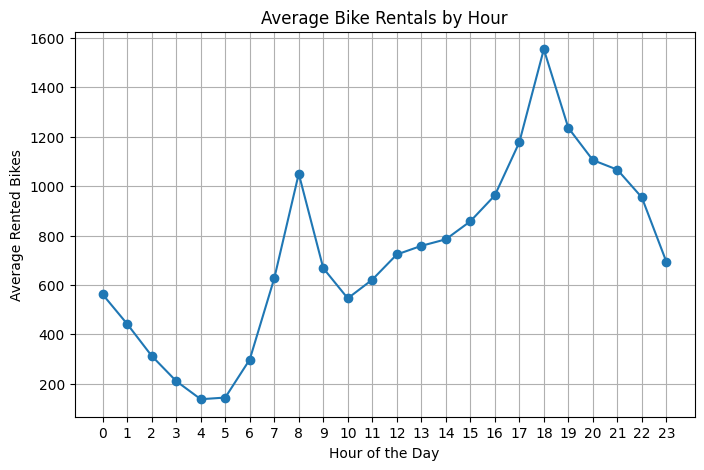

In [16]:
hourly_demand = df.groupby('Hour')['Rented_Bike_Count'].mean()

plt.figure(figsize=(8,5))
plt.plot(hourly_demand.index, hourly_demand.values, marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Rented Bikes')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

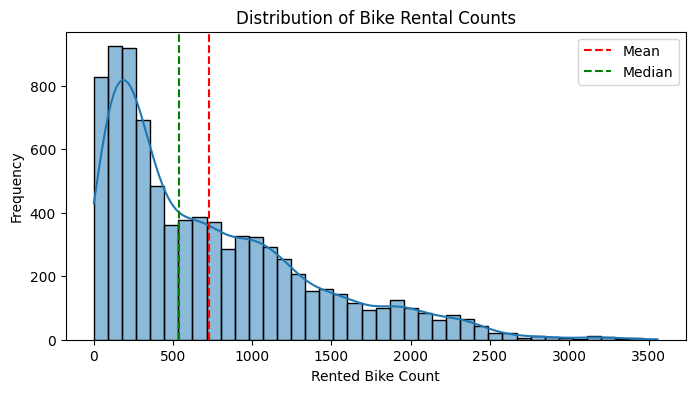

In [17]:
plt.figure(figsize=(8,4))

sns.histplot(df['Rented_Bike_Count'], bins=40, kde=True)

plt.axvline(df['Rented_Bike_Count'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(df['Rented_Bike_Count'].median(), color='green', linestyle='--', label='Median')

plt.title('Distribution of Bike Rental Counts')
plt.xlabel('Rented Bike Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

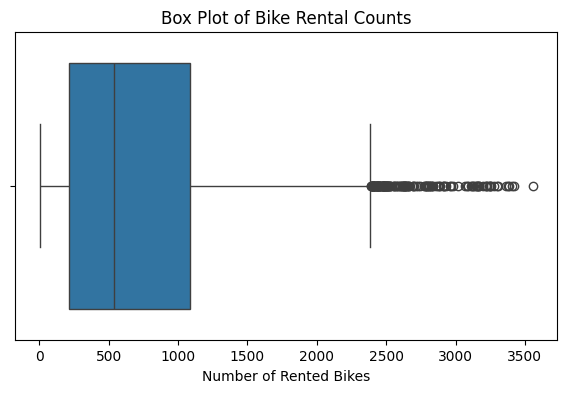

In [18]:
plt.figure(figsize=(7, 4))

sns.boxplot(x=df['Rented_Bike_Count'])

plt.title('Box Plot of Bike Rental Counts')
plt.xlabel('Number of Rented Bikes')

plt.show()

In [19]:
Q1 = df['Rented_Bike_Count'].quantile(0.25)
Q3 = df['Rented_Bike_Count'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Rented_Bike_Count'] < lower_limit) |
    (df['Rented_Bike_Count'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of outliers:", len(outliers))

Q1: 214.0
Q3: 1084.0
IQR: 870.0
Lower Limit: -1091.0
Upper Limit: 2389.0
Number of outliers: 152


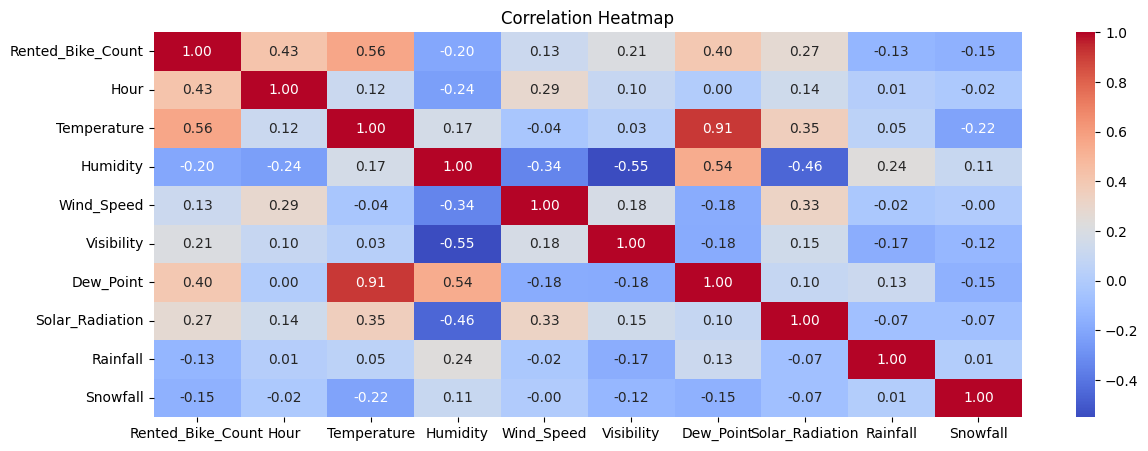

In [20]:
plt.figure(figsize=(14,5))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.xticks(rotation=0)
plt.title('Correlation Heatmap')
plt.show()

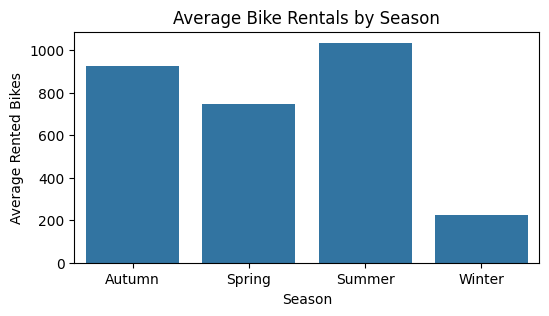

In [21]:
season_demand = df.groupby('Seasons')['Rented_Bike_Count'].mean()

plt.figure(figsize=(6,3))

sns.barplot(x=season_demand.index, y=season_demand.values)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Rented Bikes')

plt.show()

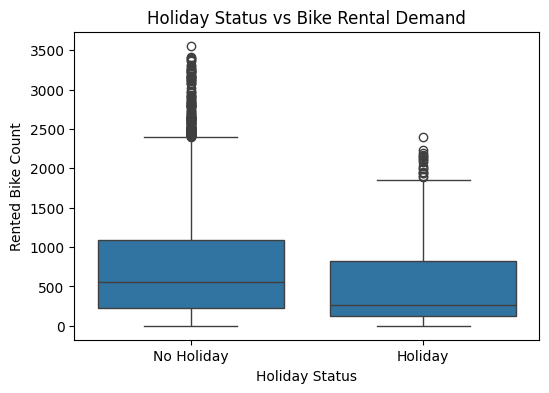

In [22]:
plt.figure(figsize=(6, 4))

sns.boxplot(data=df, x='Holiday', y='Rented_Bike_Count')

plt.title('Holiday Status vs Bike Rental Demand')
plt.xlabel('Holiday Status')
plt.ylabel('Rented Bike Count')
plt.show()

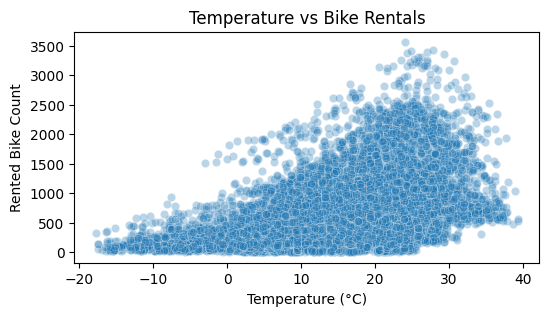

In [23]:
plt.figure(figsize=(6,3))

sns.scatterplot(data=df, x='Temperature', y='Rented_Bike_Count', alpha=0.3)

plt.title('Temperature vs Bike Rentals')
plt.xlabel('Temperature (°C)')
plt.ylabel('Rented Bike Count')
plt.show()

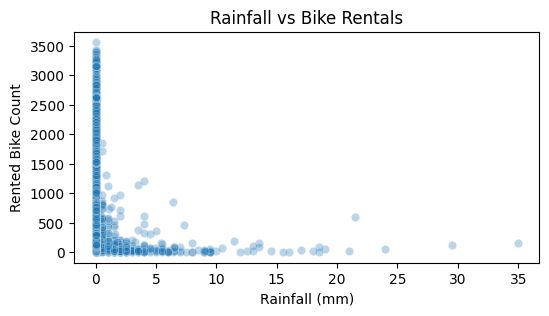

In [24]:
plt.figure(figsize=(6,3))

sns.scatterplot(data=df, x='Rainfall', y='Rented_Bike_Count', alpha=0.3)

plt.title('Rainfall vs Bike Rentals')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Rented Bike Count')
plt.show()

In [25]:
manual_data = df[['Temperature', 'Humidity', 'Rented_Bike_Count']].head(5)
display(manual_data)

,Temperature,Humidity,Rented_Bike_Count
0,-5.2,37,254
1,-5.5,38,204
2,-6.0,39,173
3,-6.2,40,107
4,-6.0,36,78


### Manual Calculation of Multiple Linear Regression

For manual calculation, five observations are selected using Temperature and Humidity as input features and Rented_Bike_Count as the target.

The regression equation is:

\[
y=b_0+b_1X_1+b_2X_2
\]

Where:
- \(X_1\) = Temperature
- \(X_2\) = Humidity
- \(y\) = Rented_Bike_Count

The design matrix includes a column of ones to calculate the intercept.

In [26]:
# Create design matrix and target vector

X_manual = np.column_stack((
    np.ones(len(manual_data)),
    manual_data[['Temperature', 'Humidity']].values
))

y_manual = manual_data['Rented_Bike_Count'].values

print("Design Matrix X:")
print(X_manual)

print("\nTarget Vector y:")
print(y_manual)

Design Matrix X:
[[ 1.  -5.2 37. ]
 [ 1.  -5.5 38. ]
 [ 1.  -6.  39. ]
 [ 1.  -6.2 40. ]
 [ 1.  -6.  36. ]]

Target Vector y:
[254 204 173 107  78]


## Feature selection and encoding

In [27]:
# Recreate input features and target
X = df.drop(columns=['Rented_Bike_Count', 'Date', 'Functioning_Day'])
y = df['Rented_Bike_Count']

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, columns=['Seasons', 'Holiday'], drop_first=True, dtype=int)

print("Encoded features:")
print(X.columns.tolist())
print("\nTarget variable (y):")
print(y.name)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Encoded features:
['Hour', 'Temperature', 'Humidity', 'Wind_Speed', 'Visibility', 'Dew_Point', 'Solar_Radiation', 'Rainfall', 'Snowfall', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_No Holiday']

Target variable (y):
Rented_Bike_Count

X shape: (8465, 13)
y shape: (8465,)


### Observation
The correlation heatmap helps identify the direction and strength of relationships between numerical features and bicycle rental demand.

- Temperature generally shows a positive relationship with rental demand.
- Humidity shows a negative relationship with rental demand.
- Hour has a relationship with rental demand because bicycle usage changes throughout the day.
- Rainfall and snowfall may reduce bicycle usage.
- Temperature and Dew_Point are strongly related to each other, indicating possible multicollinearity.
- Correlation does not prove that one feature causes a change in bicycle rental demand.

These relationships help us understand the data before building the regression model.

### train-test split chronoligically

In [28]:
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6772, 13)
Testing data: (1693, 13)


###feature scaling

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Feature scaling completed!
Training data: (6772, 13)
Testing data: (1693, 13)


In [30]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [31]:
# predict bikes rented using testing data
y_pred = model.predict(X_test_scaled)

print("Predicted bike rentals:")
print(y_pred[:10])

Predicted bike rentals:
[ 913.22257903  906.93017299  919.21563259  944.03570342  975.10424076
 1038.8816136  1091.7233794  1152.75874827 1179.29216873 1232.5530547 ]


#### Comparing actual and predicted bike rentals to check how well the model performs.

In [32]:
comparison = pd.DataFrame({
    'Actual': y_test.values[:10],
    'Predicted': y_pred[:10]
})

print(comparison)

   Actual    Predicted
0     193   913.222579
1     258   906.930173
2     678   919.215633
3    1556   944.035703
4    2369   975.104241
5    1234  1038.881614
6     922  1091.723379
7    1012  1152.758748
8    1192  1179.292169
9    1102  1232.553055


####model evaluation

In [33]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 317.28554337119886
MSE: 187977.3631672874
RMSE: 433.5635630069568
R2 Score: 0.47666914313064646


In [40]:
# Calculating Adjusted R2
n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2_score(y_test, y_pred)) * (n - 1) / (n - p - 1))
print("Adjusted R2:", adjusted_r2)

Adjusted R2: 0.4726171472168278


## Single-Feature Linear Regression

A simple Linear Regression model is trained using Temperature as the only input feature to establish a baseline. Its performance is compared with the Multiple Linear Regression model.

In [41]:
X_single = X[['Temperature']]

X_single_train = X_single.loc[X_train.index]
X_single_test = X_single.loc[X_test.index]

single_model = LinearRegression()
single_model.fit(X_single_train, y_train)

single_pred = single_model.predict(X_single_test)

print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Testing R2:", r2_score(y_test, single_pred))

Intercept: 310.5138771984917
Coefficient: 29.337795641893532
Testing R2: 0.044205590914424775


Comparison of Single and Multiple Linear Regression

In [42]:
comparison = pd.DataFrame({
    'Model': ['Single Linear Regression', 'Multiple Linear Regression'],
    'Testing R2': [
        r2_score(y_test, single_pred),
        r2_score(y_test, y_pred)
    ]
})

display(comparison)

,Model,Testing R2
0,Single Linear Regression,0.044206
1,Multiple Linear Regression,0.476669


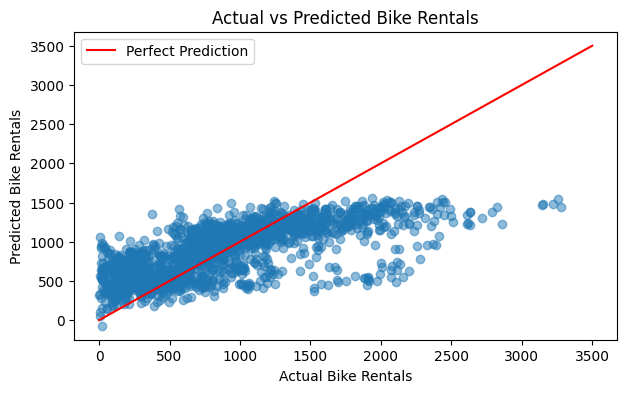

In [34]:
plt.figure(figsize=(7,4))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot([0, 3500], [0, 3500], 'r-', label='Perfect Prediction')

plt.xlabel('Actual Bike Rentals')
plt.ylabel('Predicted Bike Rentals')
plt.title('Actual vs Predicted Bike Rentals')
plt.legend()
plt.show()

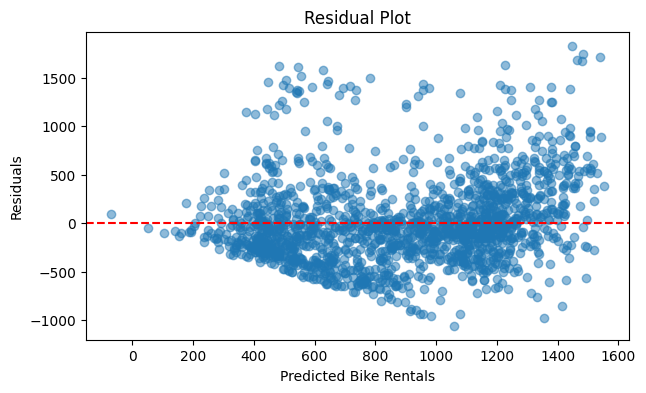

In [35]:
residuals = y_test - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Bike Rentals')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

## Residual Distribution

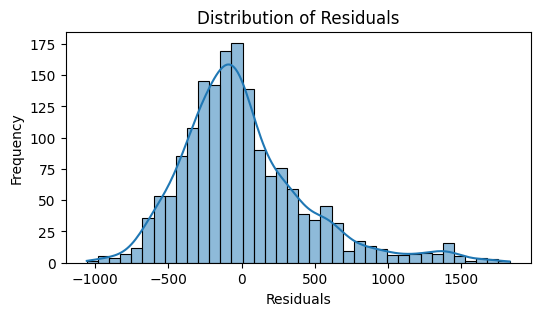

In [44]:
plt.figure(figsize=(6, 3))
sns.histplot(residuals, kde=True)
plt.title('Distribution of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()

 Multicollinearity Analysis using VIF

In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X_train.copy()

vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data.sort_values(by='VIF', ascending=False))

,Feature,VIF
5,Dew_Point,124.165443
1,Temperature,95.070348
2,Humidity,18.625029
11,Seasons_Winter,13.745845
9,Seasons_Spring,8.362467
10,Seasons_Summer,6.906395
6,Solar_Radiation,2.017904
4,Visibility,1.898425
3,Wind_Speed,1.295946
0,Hour,1.210467




The VIF analysis shows high multicollinearity among Dew_Point, Temperature, Humidity and Seasons_Winter. Dew Point and Temperature have particularly high VIF values. This indicates that some input features are strongly related to each other, which may affect the stability of regression coefficients. Most other features have low VIF values.

### Checking Linear Regression Assumptions

### 1. Linearity

The linearity assumption means that the relationship between input features and bicycle rental demand should be approximately linear. Scatter plots and the residual plot are used to examine this relationship.

### 2. Independence of Errors

The independence assumption means that the residuals (errors) should be independent of one another. Since this dataset contains hourly bicycle rental observations, errors may be related across nearby hours. Therefore, independence may be doubtful and should be considered a limitation of the model.

### 3. Homoscedasticity

Homoscedasticity means that the residuals should have approximately constant variance across all predicted values. The residual plot is used to check this assumption. If the residuals show a funnel-shaped pattern or changing spread, the assumption may be violated.

### 4. Normality of Errors

The normality assumption means that the residuals should be approximately normally distributed. A histogram of residuals is used to check this assumption. A roughly bell-shaped distribution indicates approximate normality.

### 5. No Severe Multicollinearity

This assumption means that independent variables should not have very high correlations with one another. VIF is used to identify multicollinearity. The VIF results show high multicollinearity among Temperature, Dew_Point, Humidity and Seasons_Winter, which may affect the stability of the regression coefficients.



In [36]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_})

coefficients = coefficients.sort_values(
    by='Coefficient', ascending=False)

print(coefficients)

               Feature  Coefficient
1          Temperature   245.499412
0                 Hour   191.617682
5            Dew_Point    94.398523
3           Wind_Speed    27.590262
8             Snowfall    23.958509
12  Holiday_No Holiday    23.329332
4           Visibility    -0.894834
10      Seasons_Summer   -58.984954
9       Seasons_Spring   -65.002018
7             Rainfall   -70.298905
6      Solar_Radiation   -70.603670
11      Seasons_Winter  -184.801559
2             Humidity  -201.434455


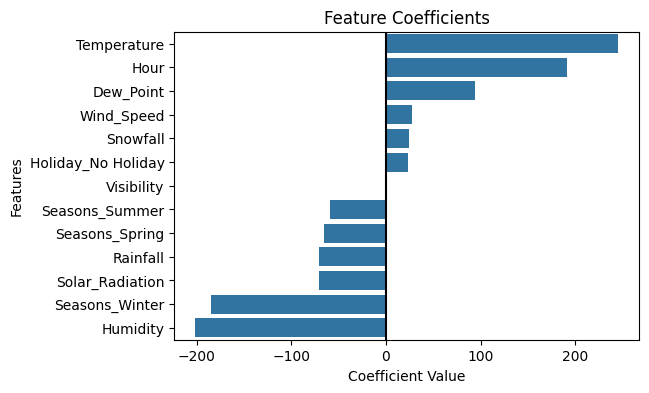

In [37]:
plt.figure(figsize=(6, 4))
sns.barplot(data=coefficients, x='Coefficient', y='Feature')
plt.title('Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.axvline(0, color='black')
plt.show()

Interpretation of Regression Coefficients

The regression coefficients indicate how each feature is associated with bicycle rental demand while keeping the other features constant.

- **Positive coefficients:** Hour, Temperature, Dew_Point, Wind_Speed, Snowfall and Holiday_No Holiday have positive coefficients. An increase in these features is associated with an increase in predicted bike rentals.
- **Negative coefficients:** Humidity, Rainfall, Solar_Radiation, Visibility, Seasons_Spring, Seasons_Summer and Seasons_Winter have negative coefficients. An increase or presence of these features is associated with a decrease in predicted bike rentals.
- Temperature and Hour have relatively large positive coefficients, while Humidity and Seasons_Winter have relatively large negative coefficients.

**Note:** These coefficients are based on standardized input features. Therefore, they represent the change in predicted rentals for a one-standard-deviation change in a numerical feature, or a one-unit change in a dummy feature. They indicate association, not causation.

In [38]:
# New sample data (weather and time conditions)
new_data = pd.DataFrame({
    'Hour': [18],
    'Temperature': [20],
    'Humidity': [50],
    'Wind_Speed': [2],
    'Visibility': [1500],
    'Dew_Point': [10],
    'Solar_Radiation': [0.5],
    'Rainfall': [0],
    'Snowfall': [0],
    'Seasons_Spring': [0],
    'Seasons_Summer': [1],
    'Seasons_Winter': [0],
    'Holiday_No Holiday': [1]
})

# Scales new data
new_data_scaled = scaler.transform(new_data)

# Predict bike rentals
prediction = model.predict(new_data_scaled)

print("Predicted Bike Rentals:", round(prediction[0]))

Predicted Bike Rentals: 1227


## Conclusion

This project uses Multiple Linear Regression to predict bicycle rental demand based on weather conditions, time and seasonal factors.

The model achieved an R² score of 0.4767 and an Adjusted R² score of 0.4726, explaining approximately 47.67% of the variation in bicycle rentals. Multiple Linear Regression performed better than Single Linear Regression, which achieved an R² score of 0.0442.

The project demonstrates how machine learning can help estimate bicycle demand and support resource planning in smart cities.

### Limitations

- Linear Regression could not capture all the variations in bicycle rental demand.
- The model's predictive performance is moderate.
- Weather changes and special events can also affect bicycle rental demand.
- Multicollinearity was observed among some input features.

### Future Scope

- Try other machine learning algorithms like Random Forest and Decision Tree to improve predictions.
- Include additional information such as traffic and special events.
- Use more data and relevant features to improve prediction accuracy.

In [47]:
final_dataset = X.copy()
final_dataset['Rented_Bike_Count'] = y

final_dataset.to_csv('Final_Prepared_Bike_Dataset.csv', index=False)

from google.colab import files
files.download('Final_Prepared_Bike_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>